# 05 · Diffusion Models: How Images Are Generated Today

Every image generator you have met in the last few years (the ones that turn a sentence into a picture) is, at its core, a network trained to do something almost embarrassingly simple: **look at a noisy image and guess the noise**. Run that guess in a loop, starting from pure static, and a picture appears.

In this notebook we build the whole idea from scratch in PyTorch, on the 8×8 handwritten digits that ship with scikit-learn, so that every experiment runs on a laptop CPU. We then measure what the sampling tricks (DDIM, guidance) actually buy, move the diffusion into the latent space of an autoencoder, and finish with how a text-to-image system is assembled from these parts.

**Builds on** (course site: [neural-networks.academy.forwardforecasting.eu](https://neural-networks.academy.forwardforecasting.eu/))

| Notebook | What we reuse |
|---|---|
| 01 neuron, 02 backprop, 03 training well | gradient descent, loss curves, why learning-rate schedules and normalisation matter |
| 05 convolutional networks | the convolutional blocks inside our denoiser |
| 08 transformer | attention, which is how real systems read the text prompt (section 7) |
| 11 vision beyond classification | the U-Net (an encoder-decoder with skip connections) |

New to PyTorch? The [AI frameworks chapter of Python 1001](https://python.academy.forwardforecasting.eu/11-ai-frameworks/) covers tensors, modules and training loops.

**Contents**
1. The generation problem, and why VAEs and GANs were hard
2. The forward process: destroying an image with noise (closed form, linear vs cosine schedule)
3. The denoiser: a small U-Net with timestep and class embeddings, and the training loss
4. Sampling: DDPM (denoising diffusion probabilistic model) and the faster DDIM (denoising diffusion implicit model), measured
5. Class-conditional generation and classifier-free guidance, measured
6. Latent diffusion: diffusion inside an autoencoder's latent space
7. How a text-to-image system fits together (diagram, table, and a small pre-trained model)
8. What this toy lacks, and safety and ethics
9. Key takeaways, exercises, references

Runtime: about 3 minutes in a clean 2-CPU environment, including the optional pre-trained demo of section 7 (models already cached; the first run downloads about 1.1 GB).

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/fborbon/academy/blob/main/neural-networks-1002/05_diffusion_models.ipynb)

**Running in Google Colab?** Choose *Runtime > Run all*. The first code cell installs only what is missing (no session restart needed). **Measured run time** in a clean 2-CPU environment like Colab's: about 3 minutes, with a peak memory of about 3.3 GB (model and data downloads were done on a fast connection). A free Colab CPU is usually slower than the machine used for the measurement, so allow more time; the timings printed in the saved outputs come from a multi-core machine.

In [ ]:
# Setup: works locally and in Google Colab. Installs only the packages that are missing.
import importlib.util, os, subprocess, sys

IN_COLAB = 'google.colab' in sys.modules
_NEEDED = {
    'diffusers': 'diffusers',
    'matplotlib': 'matplotlib',
    'numpy': 'numpy',
    'scipy': 'scipy',
    'sklearn': 'scikit-learn',
    'torch': 'torch',
    'transformers': 'transformers',
}  # import name -> pip requirement
_missing = [req for mod, req in _NEEDED.items() if importlib.util.find_spec(mod) is None]
if _missing:
    print('Installing:', ', '.join(_missing))
    _r = subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', *_missing], capture_output=True, text=True)
    if _r.returncode:
        print('WARNING: the pip install failed; continuing. Details:\n' + _r.stderr[-400:])
print(f"Environment: Python {sys.version.split()[0]} | {'Google Colab' if IN_COLAB else 'local'} | CPUs: {os.cpu_count()}")

In [1]:
import warnings
warnings.filterwarnings("ignore")
import time, math, os
import numpy as np
import matplotlib.pyplot as plt
import scipy.linalg
import torch
import torch.nn as nn
import torch.nn.functional as F
from sklearn.datasets import load_digits

torch.set_num_threads(2); torch.manual_seed(0); np.random.seed(0)
plt.rcParams["axes.grid"] = False
def count_params(m): return sum(p.numel() for p in m.parameters())
def show(ax, img, title=None):
    ax.imshow(img.reshape(8, 8), cmap="gray_r", vmin=-1, vmax=1, interpolation="nearest"); ax.axis("off")
    if title: ax.set_title(title, fontsize=8)

## 1. The generation problem, and why VAEs and GANs were hard

A **generative model** learns the distribution $p(x)$ of some data (here, images of digits) well enough to draw new samples from it. Training data are only examples, so the model has to turn "a pile of examples" into "a machine that makes more".

Before diffusion, two families dominated:

| Family | Idea | Why it was hard |
|---|---|---|
| **VAE** (variational autoencoder, [Kingma and Welling](https://arxiv.org/abs/1312.6114), 2014) | encode to a small latent vector, decode back, and push the latent distribution toward a simple Gaussian | stable and easy to train, but the pixel-wise reconstruction loss averages over plausible outputs, so samples come out **blurry** |
| **GAN** (generative adversarial network, [Goodfellow et al.](https://arxiv.org/abs/1406.2661), 2014) | a generator tries to fool a discriminator that tries to spot fakes | sharp samples, but training is a **two-player game**: it can oscillate, collapse to a few outputs (**mode collapse**) or stall, and needs a lot of tuning |
| **Diffusion** ([Sohl-Dickstein et al.](https://arxiv.org/abs/1503.03585), 2015; [Ho et al.](https://arxiv.org/abs/2006.11239), 2020) | learn to undo a gradual noising process, one small step at a time | training is a plain regression with a **single, stable loss**, covers all modes of the data; the price is **slow sampling** (many network evaluations per image) |

The diffusion bargain is: replace one hard problem (produce a whole image in one shot) by many easy ones (remove a little noise from an image). The rest of the notebook is that bargain, measured.

**Data.** `sklearn.datasets.load_digits`: 1797 grey-scale 8×8 images of handwritten digits, a copy of the UCI "Optical Recognition of Handwritten Digits" test set ([Alpaydin and Kaynak](https://archive.ics.uci.edu/dataset/80/optical+recognition+of+handwritten+digits), licence CC BY 4.0), bundled with scikit-learn, so nothing is downloaded. We rescale pixels from 0..16 to $[-1, 1]$ (the convention diffusion models use) and keep 1400 images for training and 397 for testing.

**Judging generated images.** There is no "accuracy" for a generator, so we use two measurements, both from an **independent classifier** trained only on the real training images (a small CNN, never used by the generative models):

* **class accuracy**: when we ask for a "7", does the independent classifier say "7"? This measures whether samples are recognisable and on-target;
* **Fréchet distance (FD)** between the classifier's hidden features of generated and of real test images. It is the same idea as the well-known FID (Fréchet inception distance) but with our small classifier instead of Inception. Lower is better; it measures how close the *whole distribution* of generated images is to the real one.

As a reference floor we also compute the FD between the real *training* images and the real *test* images: no generator can be expected to beat that.

In [2]:
d = load_digits()
X_all = torch.tensor(d.images / 16 * 2 - 1, dtype=torch.float32).unsqueeze(1)      # (1797, 1, 8, 8) in [-1, 1]
y_all = torch.tensor(d.target)
perm = torch.randperm(len(X_all), generator=torch.Generator().manual_seed(0))
X_all, y_all = X_all[perm], y_all[perm]
Xtr, ytr, Xte, yte = X_all[:1400], y_all[:1400], X_all[1400:], y_all[1400:]
print("train", tuple(Xtr.shape), "test", tuple(Xte.shape))

class Judge(nn.Module):
    # independent classifier; its hidden layer is the feature space for the Frechet distance
    def __init__(self):
        super().__init__()
        self.f = nn.Sequential(nn.Conv2d(1, 16, 3, padding=1), nn.ReLU(), nn.Conv2d(16, 32, 3, padding=1), nn.ReLU(),
                               nn.MaxPool2d(2), nn.Flatten(), nn.Linear(32 * 16, 32), nn.ReLU())
        self.o = nn.Linear(32, 10)
    def forward(self, x): return self.o(self.f(x))

judge = Judge(); opt = torch.optim.Adam(judge.parameters(), 2e-3)
for ep in range(25):
    p = torch.randperm(len(Xtr))
    for i in range(0, len(Xtr), 64):
        b = p[i:i + 64]; loss = F.cross_entropy(judge(Xtr[b]), ytr[b]); opt.zero_grad(); loss.backward(); opt.step()
judge.eval()
for q in judge.parameters(): q.requires_grad_(False)
print(f"independent classifier, accuracy on real test images: {(judge(Xte).argmax(1) == yte).float().mean():.1%}")

def feats(x): return judge.f(x).numpy().astype(np.float64)
def frechet(fa, fb, eps=1e-6):
    m1, m2 = fa.mean(0), fb.mean(0)
    c1 = np.cov(fa.T) + eps * np.eye(fa.shape[1]); c2 = np.cov(fb.T) + eps * np.eye(fb.shape[1])
    s = scipy.linalg.sqrtm(c1 @ c2).real
    return float(((m1 - m2) ** 2).sum() + np.trace(c1 + c2 - 2 * s))

F_REAL = feats(Xte)
def diversity(x, c):
    # mean pairwise pixel distance between images of the SAME class (higher = more varied)
    return float(np.mean([torch.pdist(x[c == k].flatten(1)).mean().item() for k in range(10) if (c == k).sum() > 1]))

def evaluate(x, c):
    return dict(acc=(judge(x).argmax(1) == c).float().mean().item(), fd=frechet(feats(x), F_REAL), div=diversity(x, c))

floor = evaluate(Xtr[:397], ytr[:397])
noise = evaluate(torch.randn(397, 1, 8, 8).clamp(-1, 1), yte)
print(f"reference: real train vs real test   FD = {frechet(feats(Xtr), F_REAL):.2f}   diversity = {diversity(Xte, yte):.2f}")
print(f"reference: pure noise                FD = {noise['fd']:.2f}   class accuracy = {noise['acc']:.1%}")

train (1400, 1, 8, 8) test (397, 1, 8, 8)


independent classifier, accuracy on real test images: 97.7%


reference: real train vs real test   FD = 5.56   diversity = 4.53
reference: pure noise                FD = 630.26   class accuracy = 10.3%


## 2. The forward process: destroying an image with noise

Take a clean image $x_0$ (the subscript is the **timestep** $t$; $t=0$ is clean). The **forward process** adds a little Gaussian noise at each of $T$ steps:

$$q(x_t \mid x_{t-1}) = \mathcal{N}\big(x_t;\ \sqrt{1-\beta_t}\,x_{t-1},\ \beta_t I\big),$$

where $\beta_t \in (0,1)$ is the **noise level** of step $t$ (the "schedule") and $\mathcal{N}(\mu, \sigma^2)$ is a Gaussian with mean $\mu$ and variance $\sigma^2$. Because a sum of Gaussians is Gaussian, we do not have to loop: define $\alpha_t = 1-\beta_t$ and $\bar\alpha_t = \prod_{s \le t}\alpha_s$ (the cumulative signal that survives). Then we can jump straight to any step:

$$\boxed{q(x_t \mid x_0) = \mathcal{N}\big(x_t;\ \sqrt{\bar\alpha_t}\,x_0,\ (1-\bar\alpha_t) I\big)} \qquad\Longleftrightarrow\qquad x_t = \sqrt{\bar\alpha_t}\,x_0 + \sqrt{1-\bar\alpha_t}\,\varepsilon,\quad \varepsilon \sim \mathcal{N}(0, I).$$

So $x_t$ is a **mix of the image and noise**: at $t=0$, $\bar\alpha \approx 1$ (all image); at $t=T$, $\bar\alpha \approx 0$ (all noise). This closed form is what makes training cheap: to train at step $t$ we jump directly there in one line.

**The schedule** decides how fast we move from image to noise. The original **linear** schedule (Ho et al. 2020) raises $\beta_t$ linearly (we rescale its usual 1000-step values to our $T=100$ steps). [Nichol and Dhariwal](https://arxiv.org/abs/2102.09672) (2021) noticed that it destroys the image too early, wasting many steps on pure noise, and proposed the **cosine** schedule, $\bar\alpha_t \propto \cos^2\!\big(\tfrac{t/T + s}{1+s}\tfrac{\pi}{2}\big)$ with a small offset $s$, which keeps information alive for longer. The **signal-to-noise ratio** $\mathrm{SNR}(t) = \bar\alpha_t / (1-\bar\alpha_t)$ summarises it.

after 50 real noising steps : mean 0.492, std 0.712
closed form q(x_t | x_0)    : mean 0.492, std 0.711


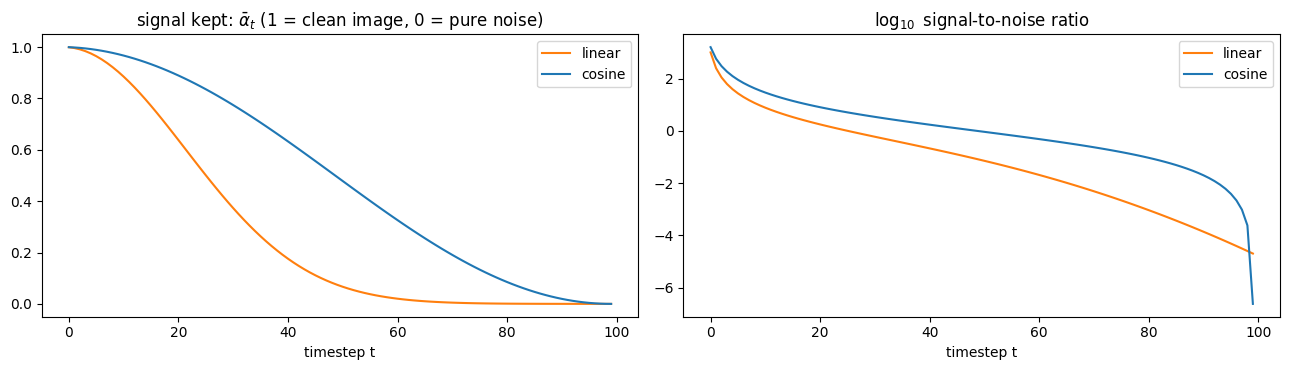

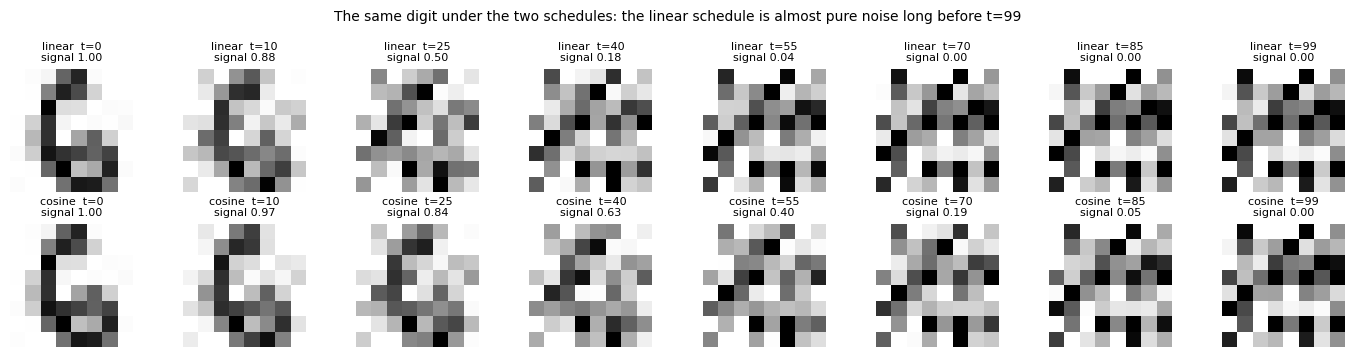

fraction of timesteps where less than 5% of the signal variance is left: {'linear': '47%', 'cosine': '15%'}


In [3]:
T = 100                                                         # number of diffusion steps (real systems use 1000)

def make_schedule(kind):
    if kind == "linear":                                        # Ho et al. 2020: beta from 1e-4 to 0.02 over 1000 steps, rescaled to T steps
        betas = torch.linspace(1e-4 * 1000 / T, 0.02 * 1000 / T, T)
    else:                                                       # Nichol and Dhariwal 2021
        s = 0.008; t = torch.arange(T + 1) / T
        f = torch.cos((t + s) / (1 + s) * math.pi / 2) ** 2
        betas = (1 - f[1:] / f[:-1]).clamp(max=0.999)
    return betas, torch.cumprod(1 - betas, 0)

SCH = {k: make_schedule(k) for k in ["linear", "cosine"]}

# 1) check the closed form against actually running the noising steps one by one
betas, ab = SCH["cosine"]
g = torch.Generator().manual_seed(1)
x = torch.full((200000,), 0.7)                                  # 200000 copies of one pixel with value 0.7
for t in range(50):
    x = (1 - betas[t]).sqrt() * x + betas[t].sqrt() * torch.randn(x.shape, generator=g)
print(f"after 50 real noising steps : mean {x.mean():.3f}, std {x.std():.3f}")
print(f"closed form q(x_t | x_0)    : mean {(ab[49].sqrt() * 0.7):.3f}, std {(1 - ab[49]).sqrt():.3f}")

# 2) the two schedules
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
for k, col in [("linear", "tab:orange"), ("cosine", "tab:blue")]:
    ab_k = SCH[k][1]
    axes[0].plot(ab_k, color=col, label=k)
    axes[1].plot(torch.log10(ab_k / (1 - ab_k)), color=col, label=k)
axes[0].set_title(r"signal kept: $\bar\alpha_t$ (1 = clean image, 0 = pure noise)"); axes[0].set_xlabel("timestep t"); axes[0].legend()
axes[1].set_title(r"$\log_{10}$ signal-to-noise ratio"); axes[1].set_xlabel("timestep t"); axes[1].legend()
plt.tight_layout(); plt.show()

# 3) images dissolving into noise
x0 = Xtr[0:1]; eps = torch.randn(1, 1, 8, 8, generator=torch.Generator().manual_seed(2))
ts = [0, 10, 25, 40, 55, 70, 85, 99]
fig, axes = plt.subplots(2, len(ts), figsize=(14, 3.6))
for r, k in enumerate(["linear", "cosine"]):
    for j, t in enumerate(ts):
        a = SCH[k][1][t]
        show(axes[r, j], (a.sqrt() * x0 + (1 - a).sqrt() * eps), f"{k}  t={t}\nsignal {a:.2f}")
plt.suptitle("The same digit under the two schedules: the linear schedule is almost pure noise long before t=99", fontsize=10)
plt.tight_layout(); plt.show()
print("fraction of timesteps where less than 5% of the signal variance is left:",
      {k: f"{(SCH[k][1] < 0.05).float().mean():.0%}" for k in SCH})

**Reading.** The closed form is not an approximation: after 50 real noising steps the simulated pixels have mean 0.492 and standard deviation 0.712, against 0.492 and 0.711 from the formula. The schedules differ a lot. With the linear schedule, 47% of the 100 timesteps have less than 5% of the signal variance left (the bottom row of images is already static from about t=55 on), so nearly half of the denoising work would be spent on noise that carries no information. The cosine schedule leaves only 15% of the steps in that regime and spreads the dissolving evenly. That is the whole argument of Nichol and Dhariwal for cosine, and it is why we train with it. (We did not train a linear-schedule model to measure the difference in sample quality; that is exercise 1.)

## 3. The denoiser: a small U-Net, and the training loss

Reversing the process means estimating $p(x_{t-1} \mid x_t)$. Ho et al. showed that, with small steps, this reverse step is also Gaussian, and that its mean can be computed from one thing only: **the noise $\varepsilon$ that was mixed into $x_t$**. So we train a network $\varepsilon_\theta(x_t, t)$ ($\theta$ = its weights) with the simplest possible loss:

$$L = \mathbb{E}_{x_0,\ t,\ \varepsilon}\ \big\|\ \varepsilon - \varepsilon_\theta\big(\sqrt{\bar\alpha_t}\,x_0 + \sqrt{1-\bar\alpha_t}\,\varepsilon,\ t\big)\big\|^2 .$$

One training step: pick an image, pick a random $t$, pick random noise $\varepsilon$, build $x_t$ with the closed form, and ask the network for $\varepsilon$. That is all.

**The score matching view, in one paragraph.** The *score* of a distribution is $\nabla_x \log p(x)$, the direction in which an image becomes more probable. For the noised image, $\nabla_{x_t}\log q(x_t \mid x_0) = -\varepsilon/\sqrt{1-\bar\alpha_t}$, so predicting the noise is the same as estimating the score of the noisy data (denoising score matching), up to a known scale. Sampling then amounts to walking uphill on the data density, step by step, with a little injected randomness: a discretised version of Langevin dynamics, or in the continuous-time view of [Song et al. (2021)](https://arxiv.org/abs/2011.13456), the reverse of a stochastic differential equation. Same model, three vocabularies.

**The network.** It must know *how noisy* its input is, so we give it the timestep $t$ through a **sinusoidal embedding** (the same idea as the positional encoding of notebook 09 of Neural Networks 1001), passed through a small MLP and **added inside every block**. We also give it a **class embedding** (digit label 0-9, plus a special "no label" token 10). During training the label is replaced by that token 15% of the time; section 5 explains why. The architecture is a U-Net (notebook 11 of Neural Networks 1001) with two resolution levels (8×8 and 4×4) and one bottleneck at 2×2.

U-Net parameters: 150,529


trained 1500 steps in 216s, final loss 0.132


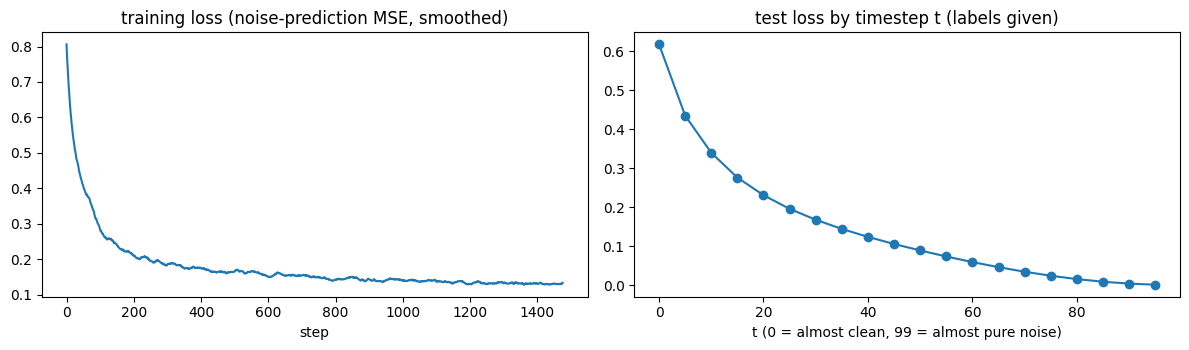

In [4]:
class Block(nn.Module):
    # conv block whose activations are shifted by the (timestep + class) embedding
    def __init__(self, cin, cout, emb):
        super().__init__()
        self.c1 = nn.Conv2d(cin, cout, 3, padding=1); self.c2 = nn.Conv2d(cout, cout, 3, padding=1)
        self.n1 = nn.GroupNorm(4, cout); self.n2 = nn.GroupNorm(4, cout)
        self.e = nn.Linear(emb, cout)
        self.skip = nn.Conv2d(cin, cout, 1) if cin != cout else nn.Identity()
    def forward(self, x, e):
        h = F.silu(self.n1(self.c1(x))) + self.e(e)[:, :, None, None]
        h = F.silu(self.n2(self.c2(h)))
        return h + self.skip(x)

def timestep_embedding(t, dim):
    # sinusoidal embedding of the integer timestep, like positional encoding in the transformer
    freqs = torch.exp(-math.log(1000) * torch.arange(dim // 2) / (dim // 2))
    a = t[:, None].float() * freqs[None]
    return torch.cat([a.sin(), a.cos()], 1)

class UNet(nn.Module):
    def __init__(self, ch=24, emb=64):
        super().__init__()
        self.emb = emb
        self.t_mlp = nn.Sequential(nn.Linear(emb, emb), nn.SiLU(), nn.Linear(emb, emb))
        self.cls = nn.Embedding(11, emb)                         # digits 0-9, and 10 = "no label"
        self.inp = nn.Conv2d(1, ch, 3, padding=1)
        self.d1 = Block(ch, ch, emb)                             # 8x8
        self.d2 = Block(ch, 2 * ch, emb)                         # 4x4
        self.mid = Block(2 * ch, 2 * ch, emb)                    # 2x2
        self.u2 = Block(4 * ch, ch, emb)                         # back to 4x4, with skip from d2
        self.u1 = Block(2 * ch, ch, emb)                         # back to 8x8, with skip from d1
        self.out = nn.Conv2d(ch, 1, 3, padding=1)
    def forward(self, x, t, c):
        e = self.t_mlp(timestep_embedding(t, self.emb)) + self.cls(c)
        h0 = self.d1(self.inp(x), e)
        h1 = self.d2(F.avg_pool2d(h0, 2), e)
        m = self.mid(F.avg_pool2d(h1, 2), e)
        u = self.u2(torch.cat([F.interpolate(m, scale_factor=2), h1], 1), e)
        u = self.u1(torch.cat([F.interpolate(u, scale_factor=2), h0], 1), e)
        return self.out(u)

NULL = 10
betas, ab = SCH["cosine"]
unet = UNet()
print(f"U-Net parameters: {count_params(unet):,}")

STEPS, BS, P_DROP = 1500, 128, 0.15
opt = torch.optim.AdamW(unet.parameters(), 2e-3)
sched = torch.optim.lr_scheduler.OneCycleLR(opt, 3e-3, total_steps=STEPS)
gen = torch.Generator().manual_seed(0)
losses, t0 = [], time.time()
for it in range(STEPS):
    b = torch.randint(0, len(Xtr), (BS,), generator=gen)
    x0, c = Xtr[b], ytr[b].clone()
    c[torch.rand(BS, generator=gen) < P_DROP] = NULL             # label dropout, for classifier-free guidance
    t = torch.randint(0, T, (BS,), generator=gen)
    eps = torch.randn(x0.shape, generator=gen)
    a = ab[t][:, None, None, None]
    xt = a.sqrt() * x0 + (1 - a).sqrt() * eps                    # closed-form forward process
    loss = F.mse_loss(unet(xt, t, c), eps)
    opt.zero_grad(); loss.backward(); opt.step(); sched.step()
    losses.append(loss.item())
unet.eval()
print(f"trained {STEPS} steps in {time.time() - t0:.0f}s, final loss {np.mean(losses[-50:]):.3f}")

# what the loss looks like per timestep (on test images)
with torch.no_grad():
    per_t = []
    for t_ in range(0, T, 5):
        tt = torch.full((len(Xte),), t_); e_ = torch.randn(Xte.shape, generator=torch.Generator().manual_seed(3))
        a_ = ab[t_]; xt_ = a_.sqrt() * Xte + (1 - a_).sqrt() * e_
        per_t.append(F.mse_loss(unet(xt_, tt, yte), e_).item())
fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
axes[0].plot(np.convolve(losses, np.ones(25) / 25, mode="valid")); axes[0].set_title("training loss (noise-prediction MSE, smoothed)"); axes[0].set_xlabel("step")
axes[1].plot(range(0, T, 5), per_t, "o-"); axes[1].set_title("test loss by timestep t (labels given)"); axes[1].set_xlabel("t (0 = almost clean, 99 = almost pure noise)")
plt.tight_layout(); plt.show()

**Reading.** The network has 150,529 parameters and trains in about 1500 steps; the loss drops from about 1 (predicting zero noise) to 0.13. The right-hand plot is the interesting one: the error is **largest at small $t$** (about 0.6) and almost zero at large $t$. That is natural. When the image is nearly pure noise, the noise is the input, so guessing it is easy; when the image is nearly clean, the noise is tiny and hard to tell apart from genuine fine detail in the digit. The hardest decisions of generation are therefore the last steps, where the details are decided. (The absolute timing printed above depends on the machine; on a busy laptop it can be several times longer than on an idle one.)

## 4. Sampling: DDPM and the faster DDIM

**Ancestral sampling (DDPM).** Start from pure noise $x_T \sim \mathcal{N}(0, I)$ and repeat for $t = T, \dots, 1$: ask the network for $\hat\varepsilon$, estimate the clean image $\hat x_0 = (x_t - \sqrt{1-\bar\alpha_t}\,\hat\varepsilon)/\sqrt{\bar\alpha_t}$, compute the mean of the Gaussian $q(x_{t-1}\mid x_t, \hat x_0)$ and **add fresh noise** of variance $\tilde\beta_t = \beta_t(1-\bar\alpha_{t-1})/(1-\bar\alpha_t)$. It needs one network call per training step, so $T$ calls.

**DDIM** ([Song, Meng and Ermon, 2021](https://arxiv.org/abs/2010.02502)) observed that the *same trained network* supports a family of samplers, including a **deterministic** one ($\eta = 0$, where $\eta$ is the amount of fresh noise injected) that can also **skip steps**: pick a subsequence of timesteps, for example every 5th, and jump between them:

$$x_{t'} = \sqrt{\bar\alpha_{t'}}\,\hat x_0 + \sqrt{1-\bar\alpha_{t'}-\sigma^2}\,\hat\varepsilon + \sigma\,z,\qquad \sigma = \eta\sqrt{\tfrac{1-\bar\alpha_{t'}}{1-\bar\alpha_t}\big(1-\tfrac{\bar\alpha_t}{\bar\alpha_{t'}}\big)},$$

with $t'$ the next (earlier) timestep of the subsequence and $z\sim\mathcal{N}(0,I)$. With $\eta=1$ and all steps it is exactly DDPM; with $\eta=0$ the mapping noise $\to$ image is deterministic, which also makes it possible to interpolate between images in noise space.

Below, the sampler is written once and used for every experiment. $w$ is the guidance scale of section 5 (0 = plain conditional model). We generate 300 digits (30 per class, same starting noise for every sampler so the comparison is fair), and score them with the independent classifier.

sampler      steps  class acc      FD  diversity  seconds
DDPM           100      97.0%    8.32       4.21      9.5
DDIM eta=0       5      99.3%   20.40       3.47      0.5
DDIM eta=0      10      97.7%   14.21       3.97      0.9
DDIM eta=0      20      96.0%   13.70       4.20      2.0
DDIM eta=0      50      95.0%   16.56       4.33      5.0
DDIM eta=0     100      94.3%   23.19       4.42      9.5
DDIM eta=1      10      99.3%   13.80       3.58      1.0
DDIM eta=1      20      99.3%    8.24       3.89      2.0
real test        -          -    5.56       4.53   (FD: train vs test)


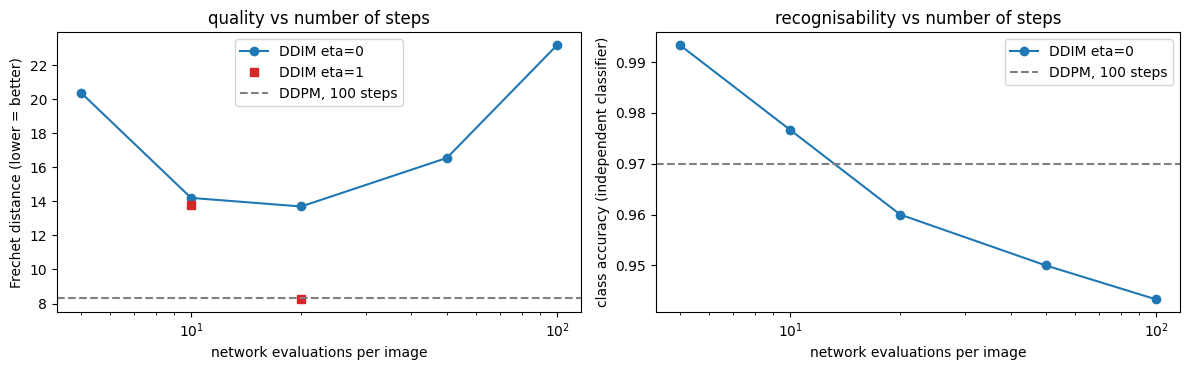

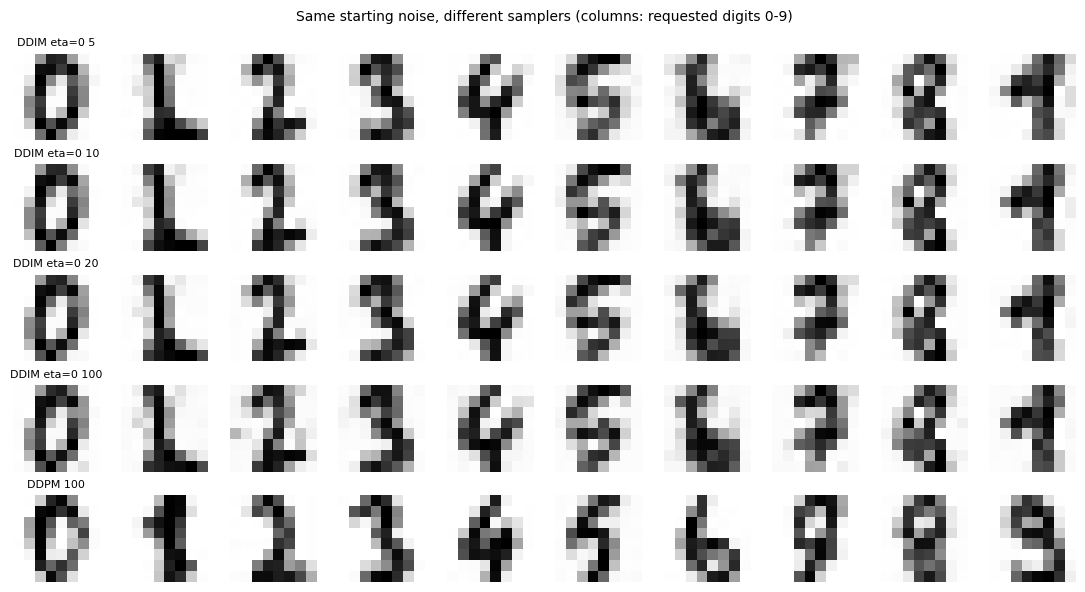

In [5]:
@torch.no_grad()
def eps_hat(net, x, t, c, w):
    tt = torch.full((len(x),), int(t))
    e_c = net(x, tt, c)
    if w == 0: return e_c
    e_u = net(x, tt, torch.full_like(c, NULL))                   # same network, label hidden
    return (1 + w) * e_c - w * e_u                               # classifier-free guidance (Ho and Salimans 2022)

@torch.no_grad()
def ddpm_sample(net, shape, c, w=0.0, seed=0):
    # ancestral sampling: T network calls, fresh noise at every step
    g = torch.Generator().manual_seed(seed); x = torch.randn(shape, generator=g)
    for t in range(T - 1, -1, -1):
        e = eps_hat(net, x, t, c, w)
        a, ap = ab[t], (ab[t - 1] if t > 0 else torch.tensor(1.0))
        x0 = ((x - (1 - a).sqrt() * e) / a.sqrt()).clamp(-1, 1)
        mean = (ap.sqrt() * betas[t] / (1 - a)) * x0 + ((1 - betas[t]).sqrt() * (1 - ap) / (1 - a)) * x
        var = betas[t] * (1 - ap) / (1 - a)
        x = mean + (var.sqrt() * torch.randn(shape, generator=g) if t > 0 else 0)
    return x.clamp(-1, 1)

@torch.no_grad()
def ddim_sample(net, shape, c, w=0.0, steps=20, eta=0.0, seed=0):
    g = torch.Generator().manual_seed(seed); x = torch.randn(shape, generator=g)
    ts = torch.linspace(T - 1, 0, steps).round().long()
    for i, t in enumerate(ts):
        e = eps_hat(net, x, t, c, w)
        a = ab[t]; ap = ab[ts[i + 1]] if i + 1 < len(ts) else torch.tensor(1.0)
        x0 = ((x - (1 - a).sqrt() * e) / a.sqrt()).clamp(-1, 1)
        sigma = eta * ((1 - ap) / (1 - a) * (1 - a / ap)).sqrt()
        x = ap.sqrt() * x0 + (1 - ap - sigma ** 2).clamp(min=0).sqrt() * e + sigma * torch.randn(shape, generator=g)
    return x.clamp(-1, 1)

N = 300
c_eval = torch.arange(N) % 10
runs = [("DDPM", T, None)] + [(f"DDIM eta=0", s, 0.0) for s in (5, 10, 20, 50, 100)] + [("DDIM eta=1", s, 1.0) for s in (10, 20)]
results, samples = [], {}
for name, steps, eta in runs:
    t0 = time.time()
    xs = ddpm_sample(unet, (N, 1, 8, 8), c_eval) if name == "DDPM" else ddim_sample(unet, (N, 1, 8, 8), c_eval, steps=steps, eta=eta)
    dt = time.time() - t0
    r = evaluate(xs, c_eval); r.update(name=name, steps=steps, secs=dt); results.append(r); samples[(name, steps)] = xs
print(f"{'sampler':12s} {'steps':>5s} {'class acc':>10s} {'FD':>7s} {'diversity':>10s} {'seconds':>8s}")
for r in results:
    print(f"{r['name']:12s} {r['steps']:5d} {r['acc']:10.1%} {r['fd']:7.2f} {r['div']:10.2f} {r['secs']:8.1f}")
print(f"{'real test':12s} {'-':>5s} {'-':>10s} {frechet(feats(Xtr), F_REAL):7.2f} {diversity(Xte, yte):10.2f}   (FD: train vs test)")

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
dd = [r for r in results if r["name"] == "DDIM eta=0"]
axes[0].plot([r["steps"] for r in dd], [r["fd"] for r in dd], "o-", label="DDIM eta=0")
for r in results:
    if r["name"] == "DDIM eta=1": axes[0].plot(r["steps"], r["fd"], "s", color="tab:red", label="DDIM eta=1" if r["steps"] == 10 else None)
axes[0].axhline(results[0]["fd"], color="gray", ls="--", label="DDPM, 100 steps")
axes[0].set_xscale("log"); axes[0].set_xlabel("network evaluations per image"); axes[0].set_ylabel("Frechet distance (lower = better)"); axes[0].legend(); axes[0].set_title("quality vs number of steps")
axes[1].plot([r["steps"] for r in dd], [r["acc"] for r in dd], "o-", label="DDIM eta=0")
axes[1].axhline(results[0]["acc"], color="gray", ls="--", label="DDPM, 100 steps")
axes[1].set_xscale("log"); axes[1].set_xlabel("network evaluations per image"); axes[1].set_ylabel("class accuracy (independent classifier)"); axes[1].legend(); axes[1].set_title("recognisability vs number of steps")
plt.tight_layout(); plt.show()

rows = [("DDIM eta=0", 5), ("DDIM eta=0", 10), ("DDIM eta=0", 20), ("DDIM eta=0", 100), ("DDPM", T)]
fig, axes = plt.subplots(len(rows), 10, figsize=(11, 1.2 * len(rows)))
for r, key in enumerate(rows):
    for k in range(10):
        show(axes[r, k], samples[key][k], f"{key[0]} {key[1]}" if k == 0 else None)
plt.suptitle("Same starting noise, different samplers (columns: requested digits 0-9)", fontsize=10)
plt.tight_layout(); plt.show()

**Reading.** Three things stand out. (1) **Ancestral DDPM with 100 steps** is the best on distribution quality: FD 8.3 (the floor between real train and real test images is 5.6), 97.0% of the samples recognised as the requested digit, diversity 4.21 against 4.53 for real data. (2) **DDIM with eta=1 and 20 steps** reaches the same FD (8.2) with a fifth of the network calls: the speed-up is real. (3) The **deterministic** DDIM (eta=0) is more surprising: it is fine with 10 to 20 steps (FD 14.2 and 13.7), clearly worse with 5 steps (FD 20.4; the images are smooth and less varied, diversity 3.47), and **it also gets worse with more steps** (FD 23.2 at 100 steps, which is deterministic but not better than the 20-step run). Theory says more steps should converge to the same answer; what we measured is the behaviour of an imperfect network, whose small errors accumulate along a deterministic path while the fresh noise of ancestral sampling keeps correcting them. This is one network and one seed, with 300 samples per row, so differences of a few FD points are within noise; the ordering DDPM and eta=1 better than eta=0 is large enough to trust, the exact curve of eta=0 is not. Class accuracy barely separates the samplers (94 to 99% everywhere), which is why we also measure FD and diversity: the classifier only says whether a digit is recognisable, not whether the *distribution* is right.

## 5. Class-conditional generation and classifier-free guidance

Our network already receives the digit label, so we can ask for a "7". A conditional model, however, often produces images that are only *loosely* tied to the label. **Classifier-free guidance** ([Ho and Salimans, 2022](https://arxiv.org/abs/2207.12598)) sharpens the tie with one trick and no extra network. During training the label is sometimes hidden (we used the "no label" token 15% of the time), so **one network learns both** the conditional noise estimate $\varepsilon_\theta(x_t, t, c)$ and the unconditional one $\varepsilon_\theta(x_t, t, \varnothing)$. At sampling time we extrapolate away from the unconditional one:

$$\tilde\varepsilon = (1+w)\,\varepsilon_\theta(x_t, t, c) - w\,\varepsilon_\theta(x_t, t, \varnothing),$$

where $w \ge 0$ is the **guidance scale** (the symbol $c$ is the class, $\varnothing$ the empty label). It costs **two network calls per step** instead of one. Larger $w$ pushes samples harder toward "what makes a $c$ a $c$", which should raise class accuracy and lower diversity: the central quality-versus-variety trade-off of every text-to-image system. We measure it with the independent classifier, DDIM with 20 steps, 300 images per setting.

guidance w  class acc      FD  diversity
      0.00      96.0%   13.70       4.20
      0.25      99.7%   12.97       4.01
      0.50     100.0%   19.92       3.88
      1.00      96.3%   90.79       3.81
      2.00      52.7%  355.45       4.11
      4.00       5.7%  546.82       4.09
 real test                          4.53


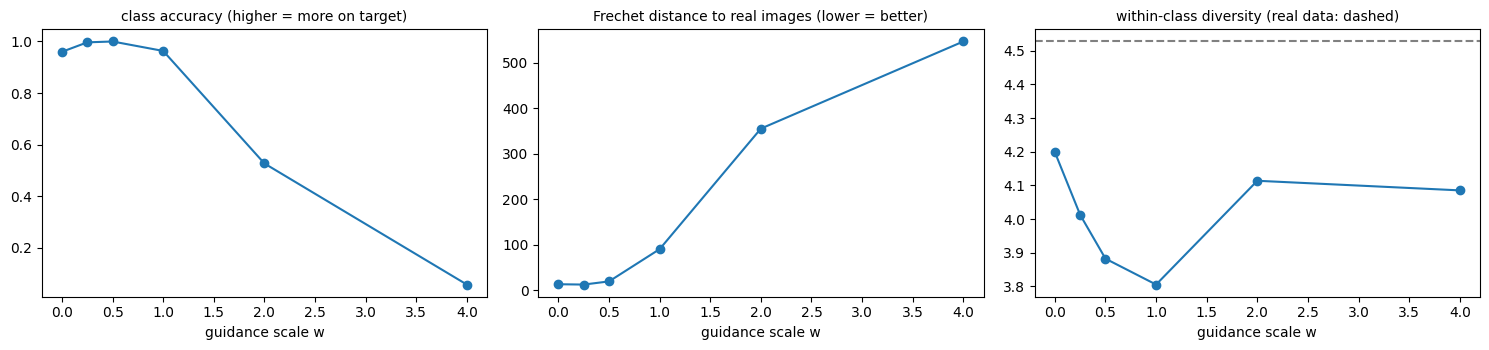

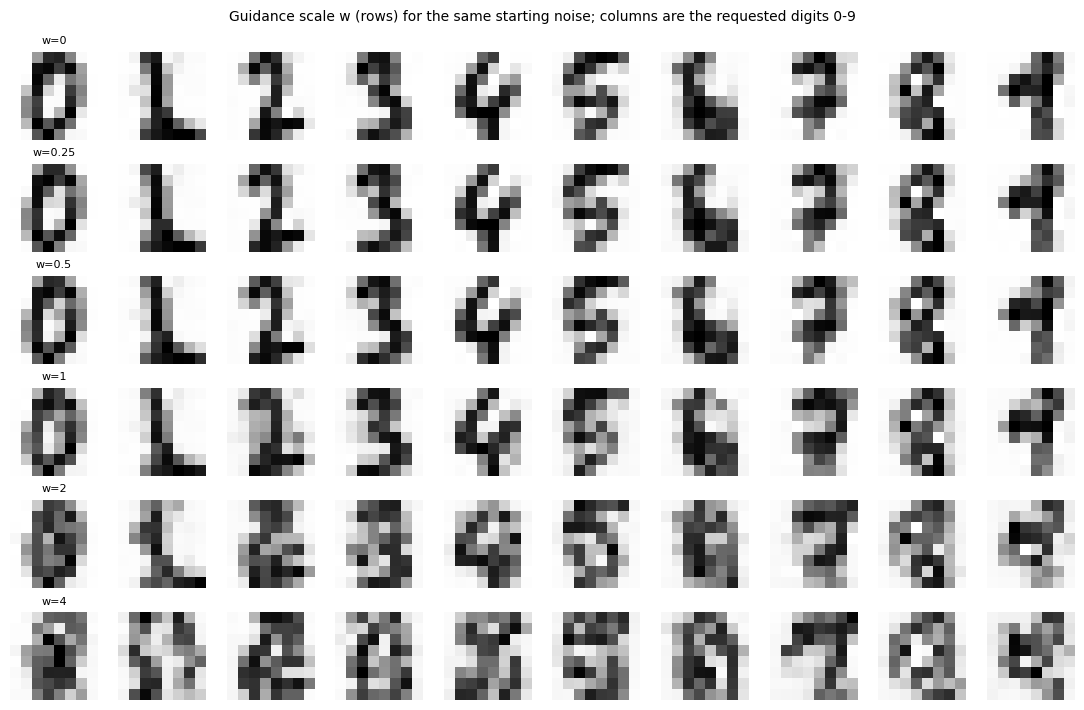

In [6]:
ws = [0, 0.25, 0.5, 1, 2, 4]
gres, gsamples = [], {}
for w in ws:
    xs = ddim_sample(unet, (N, 1, 8, 8), c_eval, w=w, steps=20)
    r = evaluate(xs, c_eval); r["w"] = w; gres.append(r); gsamples[w] = xs
print(f"{'guidance w':>10s} {'class acc':>10s} {'FD':>7s} {'diversity':>10s}")
for r in gres:
    print(f"{r['w']:10.2f} {r['acc']:10.1%} {r['fd']:7.2f} {r['div']:10.2f}")
print(f"{'real test':>10s} {'':>10s} {'':>7s} {diversity(Xte, yte):10.2f}")

fig, axes = plt.subplots(1, 3, figsize=(15, 3.6))
for ax, key, title in zip(axes, ["acc", "fd", "div"], ["class accuracy (higher = more on target)", "Frechet distance to real images (lower = better)", "within-class diversity (real data: dashed)"]):
    ax.plot(ws, [r[key] for r in gres], "o-"); ax.set_xlabel("guidance scale w"); ax.set_title(title, fontsize=10)
axes[2].axhline(diversity(Xte, yte), color="gray", ls="--")
plt.tight_layout(); plt.show()

fig, axes = plt.subplots(len(ws), 10, figsize=(11, 1.2 * len(ws)))
for r, w in enumerate(ws):
    for k in range(10):
        show(axes[r, k], gsamples[w][k], f"w={w}" if k == 0 else None)
plt.suptitle("Guidance scale w (rows) for the same starting noise; columns are the requested digits 0-9", fontsize=10)
plt.tight_layout(); plt.show()

**Reading.** For small guidance the textbook picture holds: accuracy rises from 96.0% (w=0) to 99.7% (w=0.25) and 100% (w=0.5), while diversity falls from 4.20 to 3.88, more on target and less varied. FD is best near w=0.25 (13.0) and worsens at 0.5 (19.9): the samples become more typical and less like the whole real distribution. Beyond that the toy **breaks**: at w=1 FD jumps to 91, at w=2 accuracy falls to 52.7% and at w=4 to 5.7%, and the images (last rows of the grid) become high-contrast texture rather than digits. The diversity column even goes back up at large $w$, which only shows that garbage is "diverse" in pixel distance, a good reminder that no single metric can be trusted alone. The reason is that the guided estimate $(1+w)\varepsilon_c - w\varepsilon_\varnothing$ extrapolates beyond what the network has seen, and our network is tiny and only saw the empty label in 15% of 1500 training steps, so the difference between its two branches is mostly error, which large $w$ amplifies. Real systems use scales of 3 to 8 because their networks are big and well trained, and often add tricks such as dynamic thresholding to keep extreme values in range.

## 6. Latent diffusion

Running diffusion on every pixel is wasteful: most pixels of a photo carry detail the eye cannot even see. [Rombach et al. (2022)](https://arxiv.org/abs/2112.10752) split the job in two:

1. a **perceptual autoencoder** (trained once, with no diffusion) that compresses an image into a small **latent** tensor and decodes it back almost without loss;
2. a **diffusion model that works only in the latent space**, which is much smaller (in Stable Diffusion, 512×512×3 pixels become 64×64×4 latents, 48 times fewer numbers), so every one of the many denoising steps is far cheaper.

Generation is: sample a latent with diffusion, decode it once to pixels. We reproduce exactly that structure on the digits: a small variational autoencoder (VAE) compresses 64 pixels into **8 latent numbers**, and a small MLP (multi-layer perceptron) denoiser, with the same timestep and class embeddings and the same schedule and samplers, runs diffusion on those 8 numbers.

The autoencoder is lightly **regularised** (a small KL (Kullback-Leibler) penalty keeps the latents close to a standard Gaussian, which is what Rombach et al. do too, with a KL or a vector-quantisation term), so that the latent space has no wild regions for the diffusion model to wander into.

In [7]:
LAT = 8
class AE(nn.Module):
    # a small VAE: the encoder outputs a mean and a log-variance per latent number
    def __init__(self):
        super().__init__()
        self.enc = nn.Sequential(nn.Flatten(), nn.Linear(64, 128), nn.SiLU(), nn.Linear(128, 2 * LAT))
        self.dec = nn.Sequential(nn.Linear(LAT, 128), nn.SiLU(), nn.Linear(128, 64), nn.Tanh())
    def encode(self, x): return self.enc(x).chunk(2, 1)            # (mean, log-variance)
    def decode(self, z): return self.dec(z).view(-1, 1, 8, 8)

torch.manual_seed(0)
BETA_KL = 0.02                                                     # weight of the KL term: a light regularisation, as in latent diffusion
ae = AE(); opt = torch.optim.Adam(ae.parameters(), 2e-3); t0 = time.time()
for it in range(2000):
    b = torch.randint(0, len(Xtr), (128,)); mu, lv = ae.encode(Xtr[b]); z = mu + torch.randn_like(mu) * (0.5 * lv).exp()
    kl = -0.5 * (1 + lv - mu ** 2 - lv.exp()).sum(1).mean()
    loss = F.mse_loss(ae.decode(z), Xtr[b]) * 64 + BETA_KL * kl; opt.zero_grad(); loss.backward(); opt.step()
ae.eval()
for q in ae.parameters(): q.requires_grad_(False)
with torch.no_grad():
    Z_tr = ae.encode(Xtr)[0]; z_mean, z_std = Z_tr.mean(0), Z_tr.std(0); rec = ae.decode(ae.encode(Xte)[0])
r_rec = evaluate(rec, yte)
print(f"autoencoder 64 -> {LAT} -> 64 trained in {time.time() - t0:.0f}s; test reconstruction MSE {F.mse_loss(rec, Xte):.4f}")
print(f"classifier accuracy on RECONSTRUCTED test images: {r_rec['acc']:.1%}  (the ceiling for anything decoded from this latent space)")

class LatentDenoiser(nn.Module):
    def __init__(self, emb=64, hid=256):
        super().__init__()
        self.emb = emb; self.cls = nn.Embedding(11, emb)
        self.t_mlp = nn.Sequential(nn.Linear(emb, emb), nn.SiLU(), nn.Linear(emb, emb))
        self.net = nn.Sequential(nn.Linear(LAT + emb, hid), nn.SiLU(), nn.Linear(hid, hid), nn.SiLU(), nn.Linear(hid, hid), nn.SiLU(), nn.Linear(hid, LAT))
    def forward(self, z, t, c):
        e = self.t_mlp(timestep_embedding(t, self.emb)) + self.cls(c)
        return self.net(torch.cat([z, e], 1))

Zn = (Z_tr - z_mean) / z_std                                       # standardise latents so the noise schedule fits them
lden = LatentDenoiser(); opt = torch.optim.AdamW(lden.parameters(), 2e-3)
LSTEPS = 2500
sched = torch.optim.lr_scheduler.OneCycleLR(opt, 3e-3, total_steps=LSTEPS)
gen = torch.Generator().manual_seed(0); t0 = time.time()
for it in range(LSTEPS):
    b = torch.randint(0, len(Zn), (256,), generator=gen)
    z0, c = Zn[b], ytr[b].clone(); c[torch.rand(256, generator=gen) < P_DROP] = NULL
    t = torch.randint(0, T, (256,), generator=gen); eps = torch.randn(z0.shape, generator=gen); a = ab[t][:, None]
    loss = F.mse_loss(lden(a.sqrt() * z0 + (1 - a).sqrt() * eps, t, c), eps)
    opt.zero_grad(); loss.backward(); opt.step(); sched.step()
lden.eval()
print(f"latent denoiser: {count_params(lden):,} parameters (pixel U-Net: {count_params(unet):,}), trained {LSTEPS} steps in {time.time() - t0:.0f}s")

autoencoder 64 -> 8 -> 64 trained in 10s; test reconstruction MSE 0.0444
classifier accuracy on RECONSTRUCTED test images: 96.2%  (the ceiling for anything decoded from this latent space)


latent denoiser: 161,352 parameters (pixel U-Net: 150,529), trained 2500 steps in 41s


model                               w  class acc      FD  diversity  sec/300 imgs


pixel diffusion (U-Net)           0.0      96.0%   13.70       4.20          1.85
latent diffusion (MLP + AE)       0.0      97.7%   15.85       3.91          0.10


pixel diffusion (U-Net)           2.0      52.7%  355.45       4.11          3.90
latent diffusion (MLP + AE)       2.0      92.7%   34.77       3.95          0.19
autoencoder reconstructions         -      96.2%    5.39       3.93


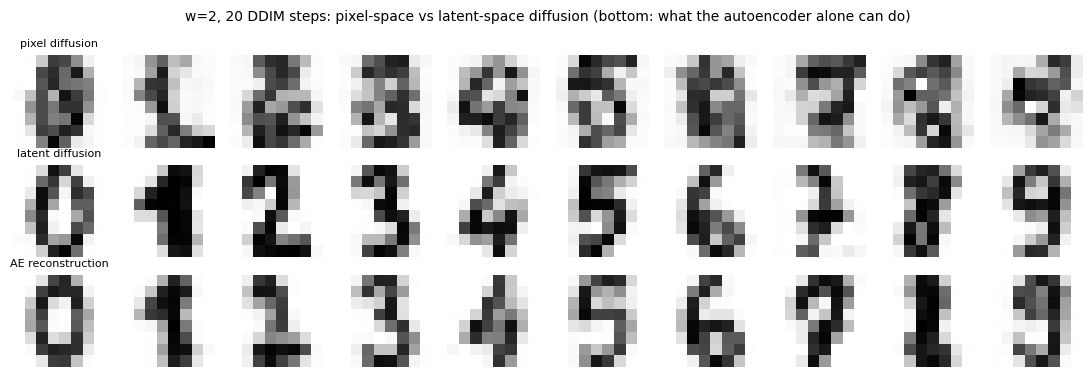

In [8]:
@torch.no_grad()
def ddim_latent(w, steps=20, eta=0.0, seed=0):
    # identical sampler, but the "image" is an 8-number latent; decode once at the end.
    # Like the clamp to [-1, 1] in pixel space, we clamp the predicted clean latent to +-3 standard deviations (without it, early
    # wrong guesses of an unbounded latent can run away and the decoder receives values it has never seen)
    g = torch.Generator().manual_seed(seed); z = torch.randn((N, LAT), generator=g)
    ts = torch.linspace(T - 1, 0, steps).round().long()
    for i, t in enumerate(ts):
        e = eps_hat(lden, z, t, c_eval, w)
        a = ab[t]; ap = ab[ts[i + 1]] if i + 1 < len(ts) else torch.tensor(1.0)
        z0 = ((z - (1 - a).sqrt() * e) / a.sqrt()).clamp(-3, 3)
        z = ap.sqrt() * z0 + (1 - ap).sqrt() * e
    return ae.decode(z * z_std + z_mean)

lat_res = []
print(f"{'model':32s} {'w':>4s} {'class acc':>10s} {'FD':>7s} {'diversity':>10s} {'sec/300 imgs':>13s}")
for w in (0, 2):
    t0 = time.time(); xs = ddim_latent(w); dt_lat = time.time() - t0
    r = evaluate(xs, c_eval); lat_res.append(r)
    t0 = time.time(); xp = ddim_sample(unet, (N, 1, 8, 8), c_eval, w=w, steps=20); dt_pix = time.time() - t0
    rp = evaluate(xp, c_eval)
    print(f"{'pixel diffusion (U-Net)':32s} {w:4.1f} {rp['acc']:10.1%} {rp['fd']:7.2f} {rp['div']:10.2f} {dt_pix:13.2f}")
    print(f"{'latent diffusion (MLP + AE)':32s} {w:4.1f} {r['acc']:10.1%} {r['fd']:7.2f} {r['div']:10.2f} {dt_lat:13.2f}")
    if w == 2: xl2, xp2 = xs, xp
print(f"{'autoencoder reconstructions':32s} {'-':>4s} {r_rec['acc']:10.1%} {r_rec['fd']:7.2f} {r_rec['div']:10.2f}")

fig, axes = plt.subplots(3, 10, figsize=(11, 3.8))
for k in range(10):
    show(axes[0, k], xp2[k], "pixel diffusion" if k == 0 else None)
    show(axes[1, k], xl2[k], "latent diffusion" if k == 0 else None)
    show(axes[2, k], rec[yte == k][0], "AE reconstruction" if k == 0 else None)
plt.suptitle("w=2, 20 DDIM steps: pixel-space vs latent-space diffusion (bottom: what the autoencoder alone can do)", fontsize=10)
plt.tight_layout(); plt.show()

**Reading.** The autoencoder compresses 64 pixels to 8 numbers and its reconstructions are still recognised 96.2% of the time (FD 5.4): this is the quality **ceiling** for anything decoded from this latent space. Diffusion in that space with no guidance reaches 97.7% class accuracy and FD 15.9, close to the pixel model (96.0%, FD 13.7), a little worse in FD, as expected from a ceiling plus the denoiser's own error. The saving is in the cost of sampling: roughly 0.1 to 0.2 s against 1.5 to 3.5 s for 300 images at 20 steps (about 10 to 15 times faster; the exact times depend on the load of the machine, see the table above), even though the two denoisers have a similar number of parameters (161 thousand and 150 thousand), because each latent step handles 8 numbers with a small MLP instead of a 64-pixel image with convolutions. With guidance w=2 the latent model keeps 92.7% accuracy where the pixel model collapsed (52.7%); do not read too much into that, since the latent sampler also clamps its predictions and the pixel model's failure comes from the weak empty-label branch discussed above. Two honest caveats: an earlier version of this cell without the clamp on the predicted latent scored only about 67 to 69% accuracy (runaway values the decoder had never seen), and a small digit image gains nothing in real quality from a latent space; the point here is the structure, whose payoff in real systems (48 times fewer numbers) is large.

## 7. How a text-to-image system fits together

A system that turns "a red bicycle leaning on a brick wall" into a picture is the pieces of this notebook plus a way to *read the sentence*:

```
 "a red bicycle ..."                                   random latent noise (e.g. 64x64x4)
        |                                                         |
  TEXT ENCODER (transformer, notebook 09 of Neural Networks 1001)                         v
  one vector per token                          +-----------------------------------+
        |   keys / values                       |  DENOISER, repeated 20-50 steps   |
        +-------- cross-attention ------------> |  U-Net (conv + attention)         |
        |         in every block                |  or diffusion transformer (DiT)   |
        |   (and, for guidance, a run           |  + timestep embedding             |
        |    with an EMPTY prompt)              +-----------------------------------+
                                                                  |  clean latent
                                                                  v
                                                       VAE DECODER (once) -> pixels
```

| Component | Role | In our toy | In a real system |
|---|---|---|---|
| **Text encoder** | turns the prompt into a sequence of vectors that carry meaning | the digit label, one of 11 embeddings | a frozen transformer (for example a CLIP (contrastive language-image pre-training) text encoder or a T5 language model), trained on huge text or image-text corpora |
| **Cross-attention conditioning** | lets every image location look at the words that matter for it: queries come from the image features, keys and values from the text vectors (notebook 09 of Neural Networks 1001) | the label embedding is *added* to every block | attention layers inside every U-Net block |
| **Latent diffusion** | cheap denoising in a compressed space ([Rombach et al.](https://arxiv.org/abs/2112.10752)) | 64 pixels to 8 numbers | roughly 8x smaller per side, 48x fewer values for a colour image |
| **Denoiser** | predicts the noise | U-Net with 150 thousand parameters | U-Net with about 1 billion parameters, or a **diffusion transformer** ([Peebles and Xie, 2023](https://arxiv.org/abs/2212.09748)) that treats latent patches as tokens |
| **Classifier-free guidance** | prompt adherence versus variety | $w$ from 0 to 4, section 5 | typically a scale of 3 to 8, with the empty prompt as the unconditional branch |
| **Decoder** | latent to pixels, once | the autoencoder's decoder | a convolutional VAE decoder |

### Optional: a real (small) pre-trained text-to-image model

The from-scratch toy above is the conceptual core; the next cell shows the real pipeline with a small open checkpoint, **[nota-ai/bk-sdm-tiny](https://huggingface.co/nota-ai/bk-sdm-tiny)** ([Kim et al., 2023](https://arxiv.org/abs/2305.15798)), a compressed version of Stable Diffusion v1.4 with a smaller U-Net (about 0.33 billion parameters in the U-Net). Licence: **CreativeML OpenRAIL-M** (use-based restrictions, read the model card). The cell downloads about 1.1 GB once (cached by Hugging Face under `~/.cache/huggingface`) and needs `pip install diffusers`; if the package or the network is not available, the cell prints why and does nothing. We generate at 256×256 with 12 steps of a fast solver, so quality is far below the model's 512×512 best, but all four ingredients above are visibly present: the text encoder, cross-attention, latent diffusion and the VAE decoder. We load only the weights we use (no safety checker, to save 600 MB): for anything beyond this classroom demo, keep the checker and read the use restrictions.

In [9]:
import importlib.util
PRETRAINED_OK = False
if importlib.util.find_spec("diffusers") is None:
    print("diffusers is not installed (pip install diffusers): skipping the optional pre-trained demo.")
else:
    try:
        os.environ["HF_HUB_DISABLE_PROGRESS_BARS"] = "1"
        import transformers
        from diffusers import StableDiffusionPipeline, DPMSolverMultistepScheduler
        from diffusers.utils import logging as diffusers_logging
        transformers.logging.disable_progress_bar(); diffusers_logging.disable_progress_bar()    # keep the notebook output short
        t0 = time.time()
        pipe = StableDiffusionPipeline.from_pretrained("nota-ai/bk-sdm-tiny", torch_dtype=torch.float32, variant="fp16",
                                                        use_safetensors=True, safety_checker=None, requires_safety_checker=False)
        pipe.scheduler = DPMSolverMultistepScheduler.from_config(pipe.scheduler.config)
        pipe.set_progress_bar_config(disable=True)
        print(f"loaded in {time.time() - t0:.0f}s;  U-Net {count_params(pipe.unet) / 1e6:.0f}M, text encoder {count_params(pipe.text_encoder) / 1e6:.0f}M, VAE {count_params(pipe.vae) / 1e6:.0f}M parameters")
        PRETRAINED_OK = True
    except Exception as err:                                      # offline, model removed, version mismatch...
        print("could not load the pre-trained model:", type(err).__name__, str(err)[:200])

loaded in 3s;  U-Net 323M, text encoder 123M, VAE 84M parameters


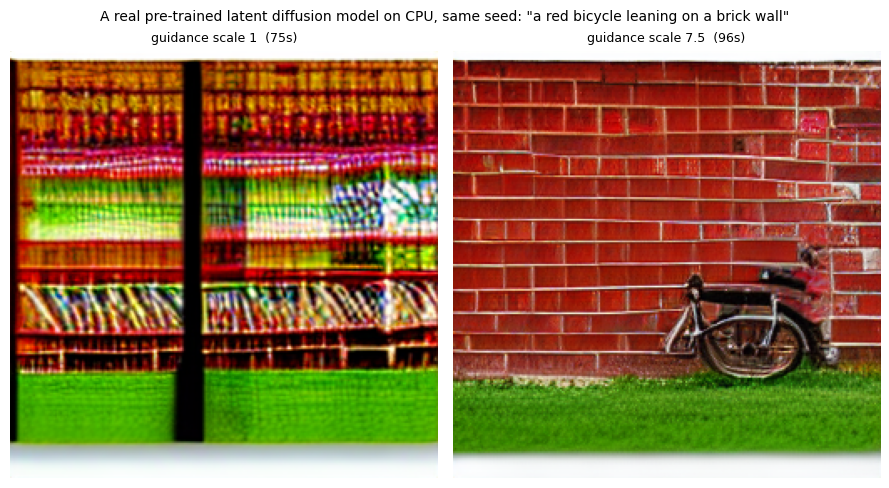

In [10]:
if PRETRAINED_OK:
    prompt = "a red bicycle leaning on a brick wall"
    scales = [1.0, 7.5]
    fig, axes = plt.subplots(1, len(scales), figsize=(9, 5))
    for k, scale in enumerate(scales):
        t0 = time.time()
        img = pipe(prompt, height=256, width=256, num_inference_steps=12, guidance_scale=scale,
                   generator=torch.Generator().manual_seed(7)).images[0]
        axes[k].imshow(img); axes[k].axis("off")
        axes[k].set_title(f"guidance scale {scale:g}  ({time.time() - t0:.0f}s)", fontsize=9)
    plt.suptitle(f'A real pre-trained latent diffusion model on CPU, same seed: "{prompt}"', fontsize=10)
    plt.tight_layout(); plt.show()
else:
    print("(skipped) The code of this cell calls pipe(prompt, height=256, width=256, num_inference_steps=12, guidance_scale=s) for s in 1, 7.5.")

**Reading.** With the same seed and a guidance scale of 1 (the prompt is only weakly enforced) the 12-step sample is saturated, striped colour noise with a red-and-green palette: some "red" and some "grass" but no scene. With a scale of 7.5 the same starting noise becomes a recognisable brick wall, grass and an object that reads as a bicycle at its base (small and not very convincing at 256×256 with a compressed model and 12 steps). That is classifier-free guidance doing in a real system what section 5 measured in the toy: the prompt is obeyed far better, at the cost of variety, and a guidance scale of 1 versus 7.5 is the difference between noise and a picture. Each image took one to three minutes on a busy laptop CPU (the timing in the titles is wall-clock for 12 steps of a 0.32-billion-parameter U-Net plus two text encodings, because guidance runs the network twice); a full-size 512×512 sample with 25 to 50 steps of a larger model is what makes GPUs the normal choice.

## 8. What this toy lacks, and safety and ethics

**Where the toy differs from the real systems.** Our images have 64 pixels, one channel and ten classes; real systems generate millions of pixels in colour from free-form text, with denoisers of about a billion parameters trained for weeks on thousands of GPUs (graphics processing units) over billions of image-text pairs. Our "FD" uses a tiny classifier instead of the standard Inception network, our 8-number latent is not a perceptual autoencoder trained with adversarial and perceptual losses, and our conditioning is a label embedding, not language. What does transfer is the mechanism: noise-prediction training, timestep conditioning, DDIM-style fast sampling, guidance and latent-space diffusion. What does **not** transfer is any claim about absolute quality, or the numbers in the tables above.

**Safety and ethics.** Image generators are powerful and the risks are concrete:

* **Copyright and consent.** Models are trained on very large web-scraped collections that include copyrighted work and personal photographs, often without the creators' knowledge. Legal status differs between countries and is being decided in courts; models can sometimes reproduce near-copies of training images. Licences such as OpenRAIL-M attach *use restrictions* to the weights. When you train or fine-tune, document the provenance of your data.
* **Deepfakes and disinformation.** Photorealistic fake images of real people, or of events that never happened, can be used for fraud, harassment, non-consensual intimate imagery and political manipulation. Do not generate or share them; report them when you find them.
* **Bias.** Generators reproduce and amplify the stereotypes in their data (who appears as a "doctor" or a "criminal"). Test prompts across groups before deploying.
* **Provenance and watermarking.** Two complementary defences exist: **invisible watermarks** embedded in the pixels or in the sampling noise by the generator (they help detect machine-made images but can be weakened by cropping, re-encoding or deliberate attack), and **signed provenance metadata** such as the open [C2PA](https://c2pa.org/) standard (cryptographically records how a file was made, but is lost when metadata is stripped). Neither is a complete solution, which is why safety filters on the prompt and the output, terms of use and platform moderation are also used. The same classifier-free-guidance mechanism is used to *steer away* from unwanted concepts with negative prompts.
* **Environmental and economic cost.** Training is expensive; generation is cheap per image but enormous in aggregate, which is the practical reason fast samplers such as DDIM matter.

## Key takeaways

* A diffusion model is a **regression for noise**: noise an image with the closed form $x_t = \sqrt{\bar\alpha_t}x_0 + \sqrt{1-\bar\alpha_t}\varepsilon$, predict $\varepsilon$ with a network that is told $t$, and minimise a mean squared error. The stability of that loss is the main reason diffusion displaced GANs.
* The **noise schedule** matters: a linear schedule spends many steps on almost pure noise; the cosine schedule keeps signal for longer.
* **DDIM** reuses the same trained network with fewer, deterministic steps; the measured price of speed is in the table of section 4.
* **Classifier-free guidance** trades diversity for fidelity with a single knob and no extra model; see the measured curves of section 5.
* **Latent diffusion** makes each step cheap by denoising a compressed code; its quality is capped by the autoencoder (section 6).
* A text-to-image system is these parts plus a **text encoder and cross-attention**; the real checkpoint of section 7 shows them working together.
* Generation brings real **copyright, deepfake, bias and provenance** problems that engineering alone does not solve.

## Exercises

1. Train the denoiser with the **linear** schedule instead of the cosine one (change `SCH["cosine"]` in the training cell and in the samplers) and compare the final FD at 20 DDIM steps.
2. Train for 500 steps instead of 1500 and repeat the DDIM step sweep. Does DDIM at few steps suffer more or less when the network is under-trained?
3. Predict $x_0$ instead of $\varepsilon$ (change the target of the loss and the formula in the sampler). Which is easier to learn at large $t$, and at small $t$?
4. Plot the guidance sweep for DDIM with 5 steps instead of 20. Does guidance interact with the number of steps?
5. Try latent sizes 2, 4 and 16. How does the autoencoder's ceiling (the classifier accuracy on reconstructions) change, and how does the latent diffusion result follow it?
6. Interpolate between two fixed noises with the deterministic DDIM sampler ($\eta=0$) and look at the images in between. Why is this impossible with DDPM?
7. Look up the model card linked in section 7 and list three limitations or restrictions it states. How would you check your own use against them?

## References

All links were checked when this notebook was written.

* Ho, Jain and Abbeel (2020). *Denoising Diffusion Probabilistic Models* (DDPM). [arXiv:2006.11239](https://arxiv.org/abs/2006.11239)
* Song, Meng and Ermon (2021). *Denoising Diffusion Implicit Models* (DDIM). [arXiv:2010.02502](https://arxiv.org/abs/2010.02502)
* Nichol and Dhariwal (2021). *Improved Denoising Diffusion Probabilistic Models* (cosine schedule). [arXiv:2102.09672](https://arxiv.org/abs/2102.09672)
* Ho and Salimans (2022). *Classifier-Free Diffusion Guidance*. [arXiv:2207.12598](https://arxiv.org/abs/2207.12598)
* Rombach, Blattmann, Lorenz, Esser and Ommer (2022). *High-Resolution Image Synthesis with Latent Diffusion Models*. [arXiv:2112.10752](https://arxiv.org/abs/2112.10752)
* Song, Sohl-Dickstein, Kingma, Kumar, Ermon and Poole (2021). *Score-Based Generative Modeling through Stochastic Differential Equations*. [arXiv:2011.13456](https://arxiv.org/abs/2011.13456)
* Peebles and Xie (2023). *Scalable Diffusion Models with Transformers* (DiT). [arXiv:2212.09748](https://arxiv.org/abs/2212.09748)
* Sohl-Dickstein, Weiss, Maheswaranathan and Ganguli (2015). *Deep Unsupervised Learning using Nonequilibrium Thermodynamics*. [arXiv:1503.03585](https://arxiv.org/abs/1503.03585)
* Kingma and Welling (2014). *Auto-Encoding Variational Bayes* (VAE). [arXiv:1312.6114](https://arxiv.org/abs/1312.6114)
* Goodfellow et al. (2014). *Generative Adversarial Networks*. [arXiv:1406.2661](https://arxiv.org/abs/1406.2661)
* Kim et al. (2023). *BK-SDM: A Lightweight, Fast, and Cheap Version of Stable Diffusion*. [arXiv:2305.15798](https://arxiv.org/abs/2305.15798); model card [nota-ai/bk-sdm-tiny](https://huggingface.co/nota-ai/bk-sdm-tiny)
* Alpaydin and Kaynak. *Optical Recognition of Handwritten Digits* (UCI), CC BY 4.0. [archive.ics.uci.edu](https://archive.ics.uci.edu/dataset/80/optical+recognition+of+handwritten+digits)
* C2PA, Coalition for Content Provenance and Authenticity. [c2pa.org](https://c2pa.org/)